In [1]:
import numpy as np
import pandas as pd

import geopandas as gpd
from shapely.geometry import Point, Polygon
import pycno

import matplotlib.pyplot as plt
from matplotlib.patches import Patch, ConnectionPatch
from matplotlib import cm

import glob
from pathlib import Path
import pickle

from scipy.cluster.vq import kmeans,vq
from sklearn.cluster import KMeans 
from sklearn import preprocessing

kc_dict = {1:'Af;Tropical, rainforest',2:'Am;Tropical, monsoon',3:'Aw;Tropical, savannah',
4:'BWh;Arid, desert, hot',5:'BWk;Arid, desert, cold',6:'BSh;Arid, steppe, hot',7:'BSk;Arid, steppe, cold',
8:'Csa;Temperate, dry summer, hot summer',9:'Csb;Temperate, dry summer, warm summer',10:'Csc;Temperate, dry summer, cold summer',11:'Cwa;Temperate, dry winter, hot summer',
12:'Cwb;Temperate, dry winter, warm summer',13:'Cwc;Temperate, dry winter, cold summer',14:'Cfa;Temperate, no dry season, hot summer',15:'Cfb;Temperate, no dry season, warm summer',
16:'Cfc;Temperate, no dry season, cold summer',17:'Dsa;Cold, dry summer, hot summer',18:'Dsb;Cold, dry summer, warm summer',19:'Dsc;Cold, dry summer, cold summer',
20:'Dsd;Cold, dry summer, very cold winter',21:'Dwa;Cold, dry winter, hot summer',22:'Dwb;Cold, dry winter, warm summer',23:'Dwc;Cold, dry winter, cold summer',
24:'Dwd;Cold, dry winter, very cold winter',25:'Dfa;Cold, no dry season, hot summer',26:'Dfb;Cold, no dry season, warm summer',27:'Dfc;Cold, no dry season, cold summer',
28:'Dfd;Cold, no dry season, very cold winter',29:'ET;Polar, tundra',30:'EF;Polar, frost'}

### Read in and clean data

In [17]:
world_shp = gpd.read_file('world_shp/world-administrative-boundaries.shp')
world_shp.set_index('name',inplace=True)

Rx_df = pd.read_csv('Rx_Master/Rx_MASTER_v2025-02-07.csv',low_memory=False)
EU_idx = (Rx_df['Country']=='Portugal')|(Rx_df['Country']=='Spain')|(Rx_df['Country']=='France')|\
(Rx_df['Country']=='Italy')|(Rx_df['Country']=='Germany')|(Rx_df['Country']=='Sweden')|(Rx_df['Country']=='United Kingdom')
EU_df = Rx_df[EU_idx]
df = EU_df

In [9]:
# keep_col = ['Latitude','Longitude','Topography','DOY','CHI','VPD','RH','PPT',
#             'BLH','Wind','T2m','FWI','FFDI','USBI','DMC','KBDI','FFMC','DC']
keep_col = ['Topography','RH_min',
            'Wind_max','T_max','Latitude']
keep_df = df[keep_col]
keep_df.replace([np.inf, -np.inf], np.nan, inplace=True)
keep_df.dropna(how='any',inplace=True)

/tmp/ipykernel_16265/498708466.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  keep_df.replace([np.inf, -np.inf], np.nan, inplace=True)
/tmp/ipykernel_16265/498708466.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  keep_df.dropna(how='any',inplace=True)


### Elbow Method
* To determine optimal number of clusters

Text(0.5, 1.0, 'Elbow curve')

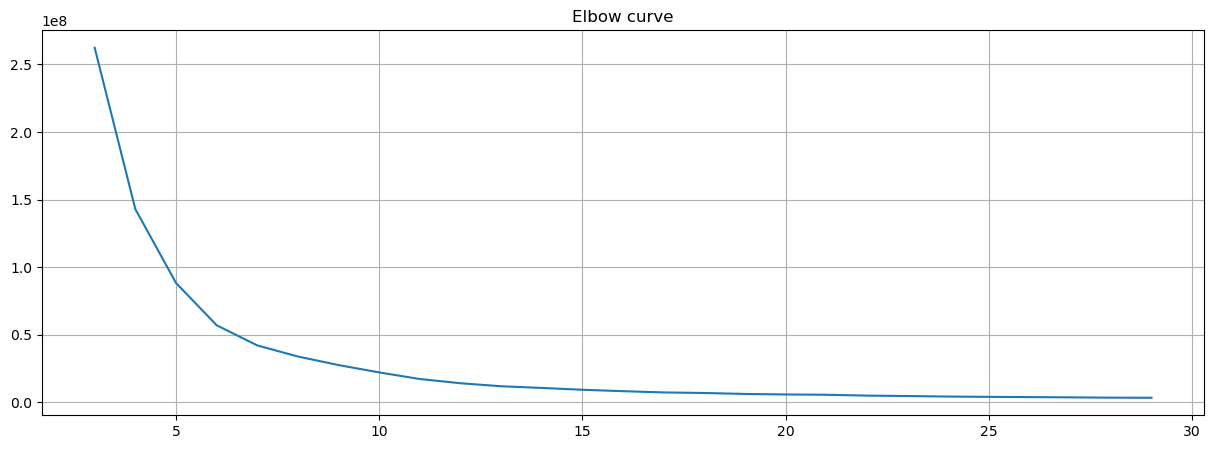

In [10]:
X = np.asarray(keep_df)
sse = []
for k in range(3,30):
    k_means = KMeans(n_clusters=k)
    k_means.fit(X)
    sse.append(k_means.inertia_)
    
fig = plt.figure(figsize=(15, 5))
plt.plot(range(3,30), sse)
plt.grid(True)
plt.title('Elbow curve')

In [11]:
keep_df

,Topography,RH_min,Wind_max,T_max,Latitude
407,1954.0,39.329903,2.051193,12.343788,42.440901
408,1954.0,39.329903,2.051193,12.343788,42.440748
409,1954.0,48.689561,1.908412,14.977582,42.439306
410,1954.0,63.244523,1.311362,15.817534,42.439620
411,1954.0,64.489754,2.323423,14.731665,42.453908
...,...,...,...,...,...
161800,245.0,60.373927,4.010945,12.032325,43.330954
161801,116.0,53.460796,2.855710,16.043613,43.438491
161802,205.0,71.476444,3.171783,12.503712,43.436085
161803,329.0,73.781622,2.559439,15.004576,43.425962


### Compute clusters

In [12]:
# Scale features so they are similar orders of magnitude
scaler = preprocessing.StandardScaler()
keep_df.loc[:,keep_col] = scaler.fit_transform(keep_df[keep_col])

/tmp/ipykernel_16265/278065325.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  keep_df.loc[:,keep_col] = scaler.fit_transform(keep_df[keep_col])


In [13]:
# Computing K-Means with k = 10
k = 10
X = np.asarray(keep_df)
centroids,_ = kmeans(X,k)

# Assign each sample to a cluster
idx,_ = vq(X,centroids)

# Add cluster number to dataframe
keep_df['k_cluster'] = idx

/tmp/ipykernel_16265/3818967732.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  keep_df['k_cluster'] = idx


In [15]:
keep_df

,Topography,RH_min,Wind_max,T_max,Latitude,k_cluster
407,2.345000,-0.958186,-0.940858,-0.152050,-0.369580,0
408,2.345000,-0.958186,-0.940858,-0.152050,-0.369613,0
409,2.345000,-0.326362,-1.008990,0.330508,-0.369926,0
410,2.345000,0.656170,-1.293891,0.484402,-0.369858,0
411,2.345000,0.740230,-0.810955,0.285452,-0.366755,1
...,...,...,...,...,...,...
161800,-0.705931,0.462391,-0.005702,-0.209115,-0.176287,2
161801,-0.936224,-0.004280,-0.556958,0.525824,-0.152933,2
161802,-0.777340,1.211866,-0.406134,-0.122749,-0.153456,2
161803,-0.555973,1.367477,-0.698333,0.335454,-0.155654,2


In [27]:
# Add columns back to clustered data
keep_df.loc[keep_df.index,'Koppen Climate'] = df.loc[keep_df.index,'Koppen Climate']
keep_df.loc[keep_df.index,'Longitude'] = df.loc[keep_df.index,'Longitude']
keep_df.loc[keep_df.index,'Latitude'] = df.loc[keep_df.index,'Latitude']
keep_df.loc[keep_df.index,'Biome (Olson)'] = df.loc[keep_df.index,'Biome (Olson)']
keep_df.loc[keep_df.index,'Ecoregion (Olson)'] = df.loc[keep_df.index,'Ecoregion (Olson)']
keep_df.loc[keep_df.index,'Country'] = df.loc[keep_df.index,'Country']
keep_df.loc[keep_df.index,'Fuelbed Group'] = df.loc[keep_df.index,'Fuelbed Group']

/tmp/ipykernel_16265/4267016729.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  keep_df.loc[keep_df.index,'Koppen Climate'] = df.loc[keep_df.index,'Koppen Climate']
/tmp/ipykernel_16265/4267016729.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  keep_df.loc[keep_df.index,'Longitude'] = df.loc[keep_df.index,'Longitude']
/tmp/ipykernel_16265/4267016729.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instea

In [30]:
pd.set_option('display.max_rows',None)
# pd.reset_option('max_rows')
keep_df.groupby(['k_cluster','Country','Fuelbed Group']).size()

k_cluster  Country         Fuelbed Group                                      
0          France          Broadleaf Deciduous Forest                              52
                           Cropland                                               129
                           Grassland                                                9
                           Mixed Broadleaf and Needleleaf Forest                   11
                           Mosaic Cropland (50-70%)/Vegetation (20-50%)           134
                           Mosaic Forest-Shrubland (50-70%)/Grassland (20-50%)     16
                           Needleleaf Evergreen                                    17
                           Sparse Vegetation                                       69
           Portugal        Broadleaf Deciduous Forest                               1
                           Needleleaf Evergreen                                     1
                           Shrubland                         

### Plot GlobalRx Clusters

In [19]:
tab10 = cm.get_cmap("tab10").colors
tab20b = cm.get_cmap("tab20b").colors
tab20c = cm.get_cmap("tab20c").colors
tab20 = cm.get_cmap("tab20").colors
Set2 = cm.get_cmap("Set2").colors
Dark2 = cm.get_cmap("Dark2").colors
Paired = cm.get_cmap("Paired").colors

biome_colors = {'Boreal Forests/Taiga':tab20[1],'Tundra':tab20c[17],'Deserts & Xeric Shrublands':tab20b[10],
               'Mediterranean Forests, Woodlands & Scrub':tab20b[8],'Montane Grasslands & Shrublands':Set2[5],
               'Flooded Grasslands & Savannas':tab20[5],'Temperate Grasslands, Savannas & Shrublands':Set2[4],
               'Tropical & Subtropical Grasslands, Savannas & Shrublands':tab20[17],
               'Temperate Broadleaf & Mixed Forests':(0.2,0.4,0),'Tropical & Subtropical Moist Broadleaf Forests':tab20[4],
               'Tropical & Subtropical Dry Broadleaf Forests':tab20[16],'Temperate Conifer Forests':Paired[11],
                'Tropical & Subtropical Coniferous Forests':tab20b[5],'Mangrove':[0.27,0.28,0.02],'Lake':[0,0,1],
                'Rock/Ice':[1,1,1]}
biome_dict = {'Boreal Forests/Taiga': 6,'Deserts & Xeric Shrublands': 13,'Flooded Grasslands & Savannas': 9,
 'Mediterranean Forests, Woodlands & Scrub': 12,'Montane Grasslands & Shrublands': 10,
 'Temperate Broadleaf & Mixed Forests': 4,'Temperate Conifer Forests': 5,'Temperate Grasslands, Savannas & Shrublands': 8,
 'Tropical & Subtropical Coniferous Forests': 3,'Tropical & Subtropical Dry Broadleaf Forests': 2,
 'Tropical & Subtropical Grasslands, Savannas & Shrublands': 7,'Tropical & Subtropical Moist Broadleaf Forests': 1,'Tundra': 11,
 'Lake': 98,'Rock/Ice': 99,'Mangrove': 14}

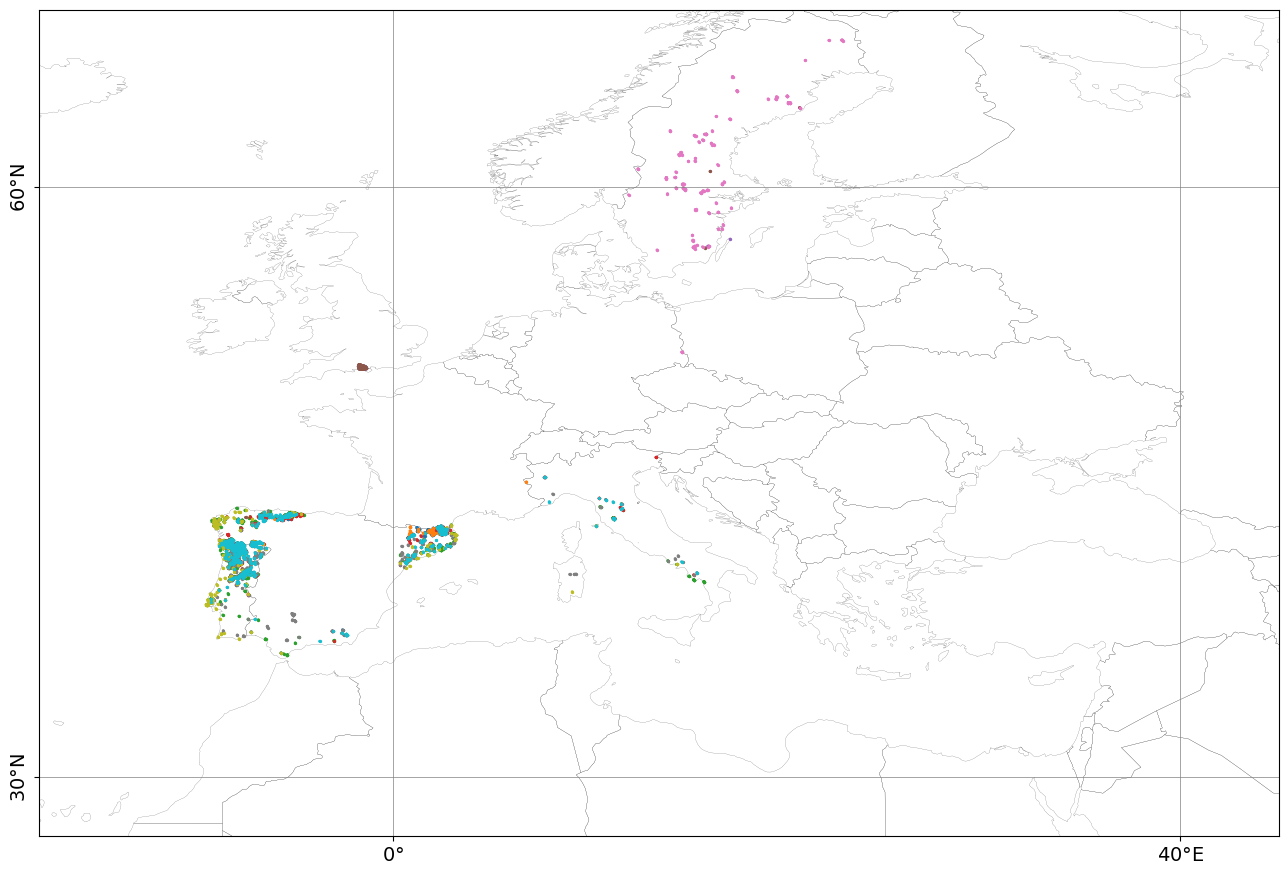

In [20]:
# Set colors for each biome
world_biomes = list(biome_colors.keys())

fig, ax = plt.subplots(figsize=(16,16))
# cno = pycno.cno()
# cno.draw('MWDB_Coasts_Countries_1.cnob')

# Display lat/lon
# ax.spines['top'].set_visible(False)
# ax.spines['right'].set_visible(False)
# ax.spines['bottom'].set_visible(False)
# ax.spines['left'].set_visible(False)

ax.set_xticks([])
ax.set_yticks([])
ax.spines[:].set_visible(True)

xticks = [-160,-120,-80,-40,0,40,80,120,160]
yticks = [-60,-30,0,30,60]
ax.get_xaxis().set_ticks(xticks)
ax.get_yaxis().set_ticks(yticks)
xticklabels = [str(abs(i))+'$\degree$W' if i<0 else str(abs(i))+'$\degree$E' for i in xticks]
xticklabels[4] = '0$\degree$'
yticklabels = [str(abs(i))+'$\degree$S' if i<0 else str(abs(i))+'$\degree$N' for i in yticks]
yticklabels[2] = '0$\degree$'
ax.set_xticklabels(xticklabels,fontsize=14)
ax.set_yticklabels(yticklabels,fontsize=14,rotation=90,rotation_mode='default',va='center')
ax.grid(color='gray',linewidth=0.5)

# eco_shp = gpd.read_file('official_teow/wwf_terr_ecos.shp').to_crs('EPSG:4326')
# for biome in world_biomes:
#     eco_shp.loc[eco_shp['BIOME']==biome_dict[biome],'BIOME'] = biome
    
# eco_shp.plot(color=eco_shp['BIOME'].map(biome_colors),ax=ax,categories=world_biomes,aspect='equal',edgecolor='None')

world_shp = gpd.read_file(glob.glob('world_shp/*.shp')[0]).to_crs('EPSG:4326')
bounds = world_shp['geometry'].bounds
# xlim = [bounds['minx'].min(),bounds['maxx'].max()]
# ylim = [bounds['miny'].min(),bounds['maxy'].max()]
ax.set_xlim([-18,45])
ax.set_ylim([27,69])
world_shp.plot(ax=ax,facecolor='None',edgecolor='black',aspect='equal',linewidth=0.1)

ax.scatter(keep_df['Longitude'].values,keep_df['Latitude'].values,c=keep_df['k_cluster'].values,
               marker='.',s=5,cmap='tab10',label='GlobalRx Records (v2024)')

clusters = np.unique(keep_df['k_cluster'].values)
clust_dict = {i:tab10[i] for i in clusters}
for cluster in clusters:
    ax.scatter(keep_df.loc[keep_df['k_cluster']==cluster,'Longitude'],
               keep_df.loc[keep_df['k_cluster']==cluster,'Latitude'],
               color=clust_dict[cluster],marker='o',s=2,cmap='tab10',
               label='GlobalRx Records (v2024)')
    
# leg = ax.legend(loc='lower left',fontsize=14,handletextpad=0.1)
# leg.legendHandles[0]._sizes = [60]
# countries = ['Australia','Brazil','Canada','France','Italy','Japan','Mexico','Portugal','Russian Federation','South Africa','Spain',
#              'Sweden','Thailand','United States of America','U.K. of Great Britain and Northern Ireland']
# for country in countries:
#     country_shp = world_shp[world_shp['name']==country]
#     country_shp.plot(ax=ax,facecolor='None',edgecolor='Black',aspect='equal',linewidth=1)
# plt.savefig('Figures/GlobalRx_countries_biomes.png',bbox_inches='tight',transparent=True)

### HDBSCAN

In [2]:
from sklearn.cluster import DBSCAN, HDBSCAN

ImportError: cannot import name 'HDBSCAN' from 'sklearn.cluster' (/gpfs/home/zna22eeu/.conda/envs/geo_env2/lib/python3.8/site-packages/sklearn/cluster/__init__.py)

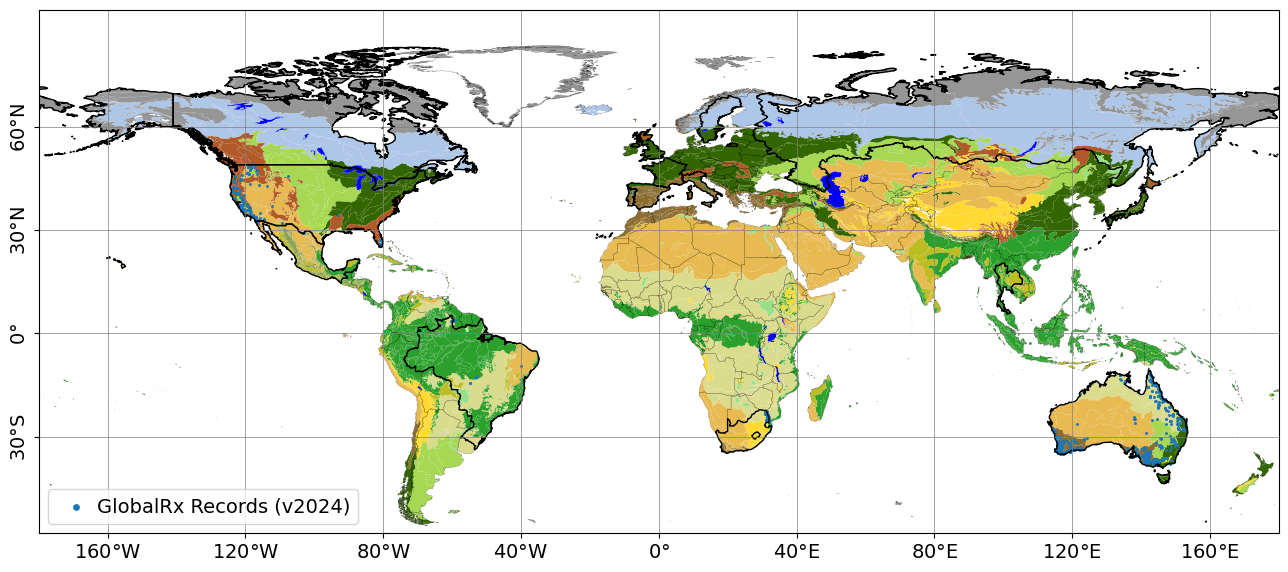

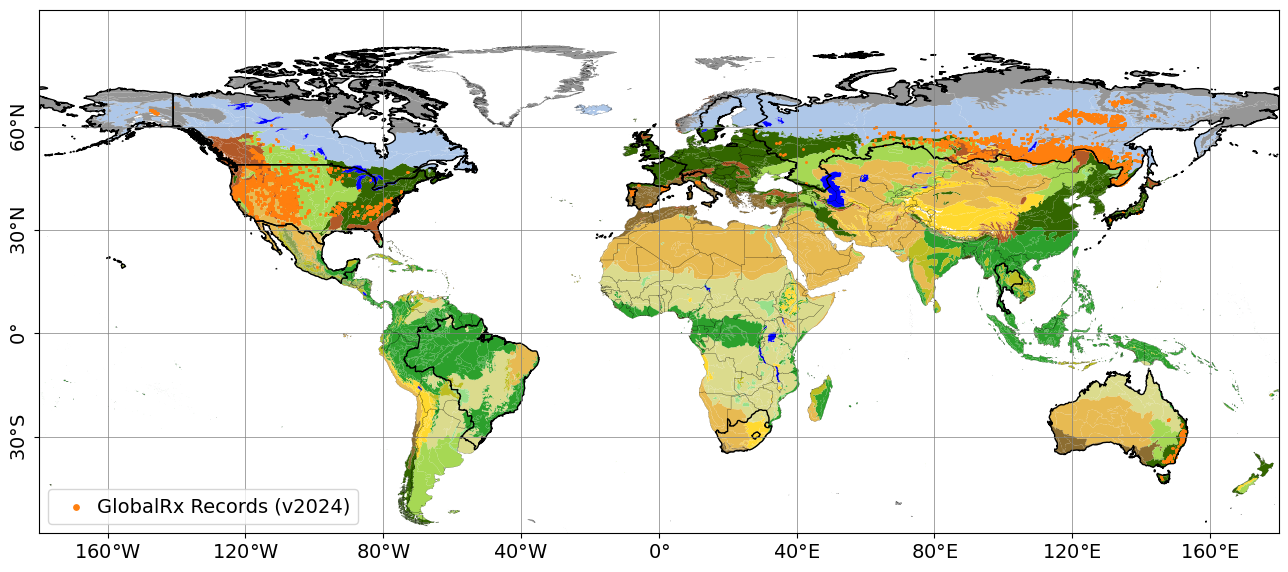

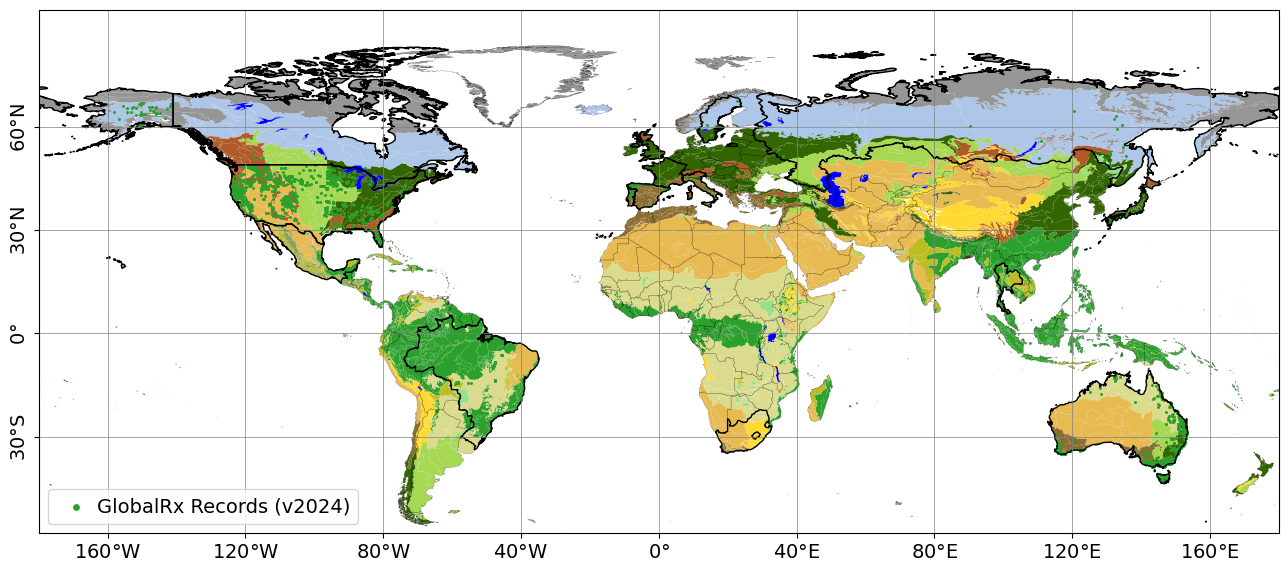

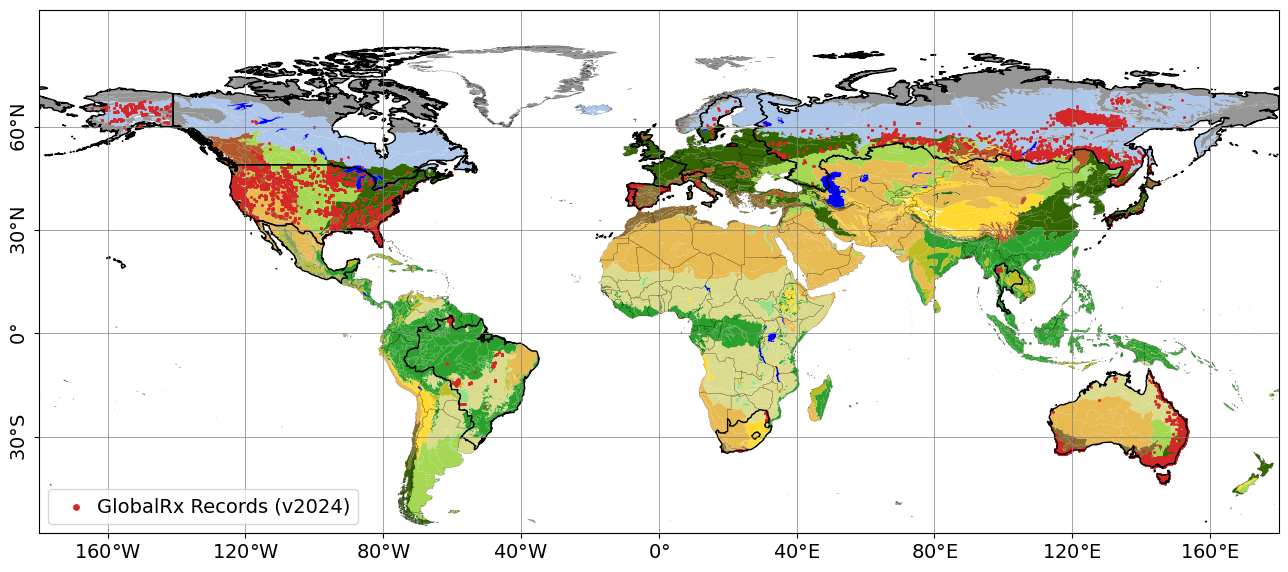

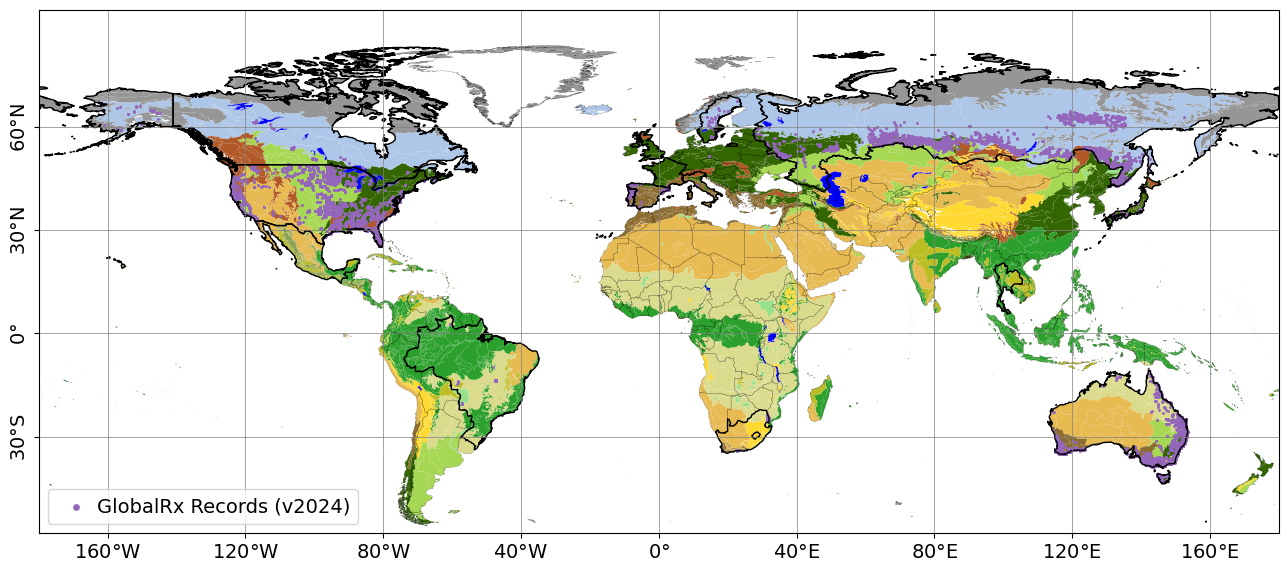

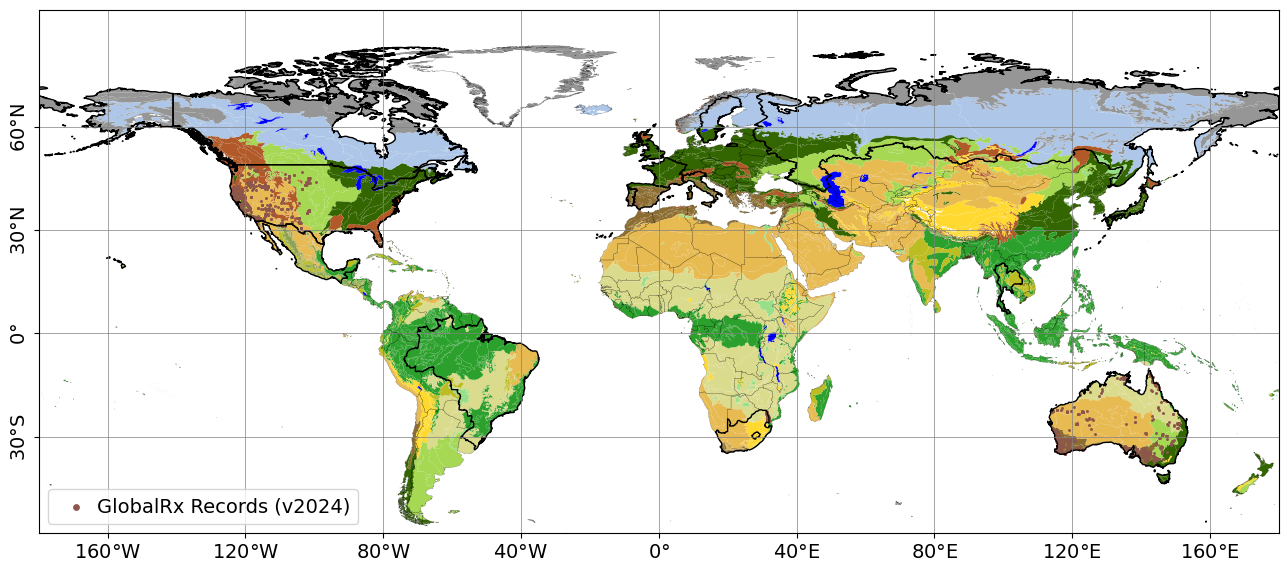

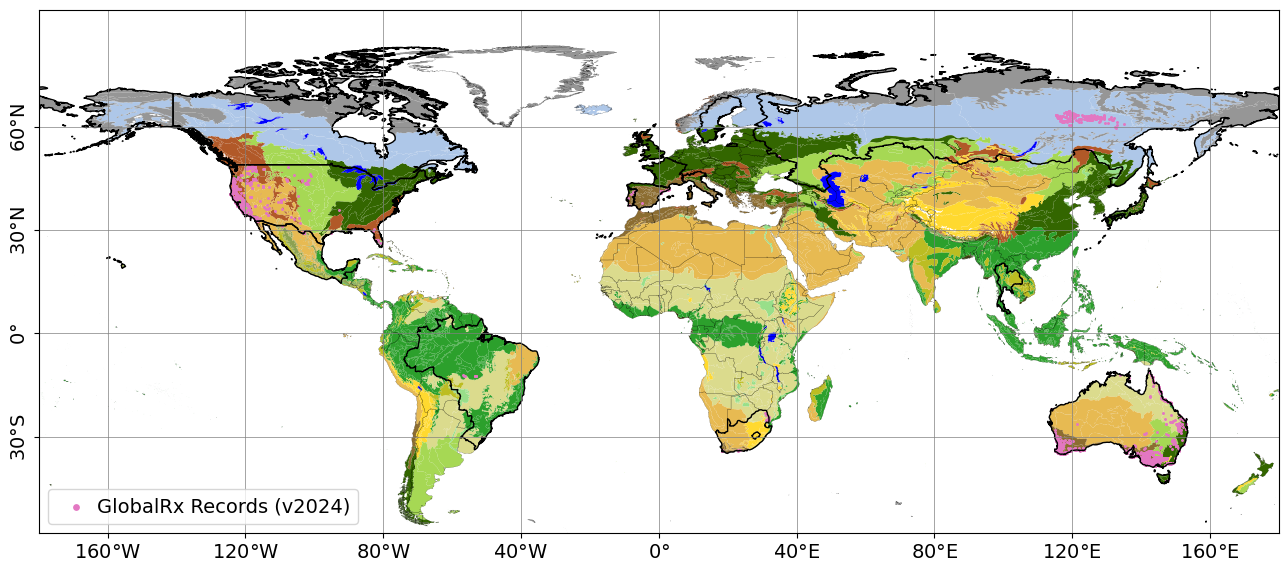

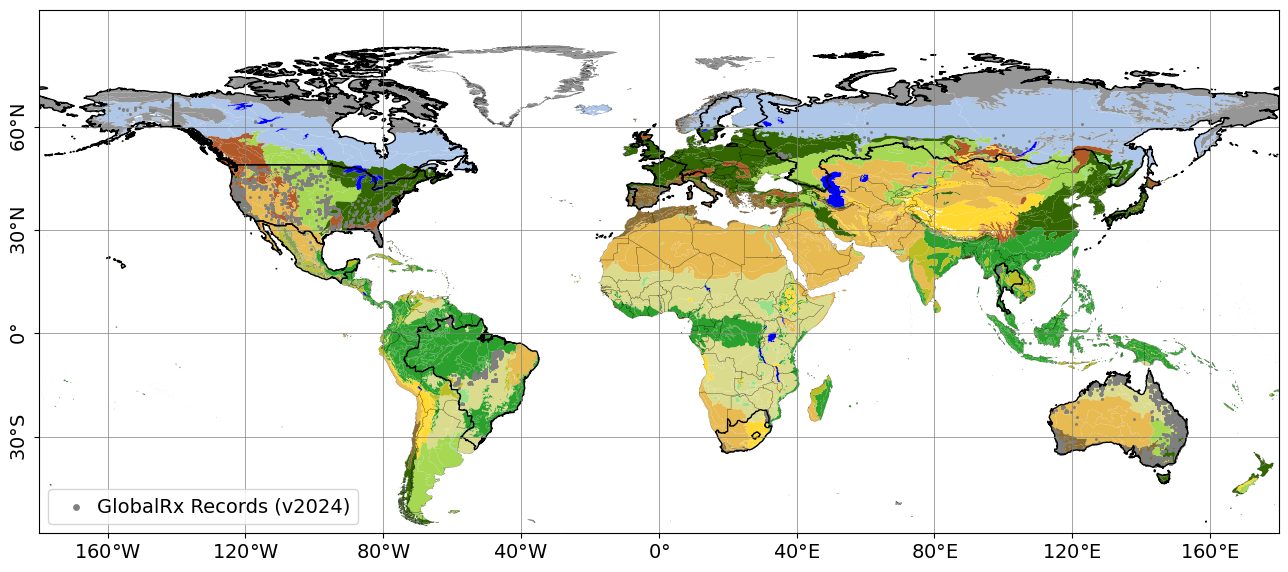

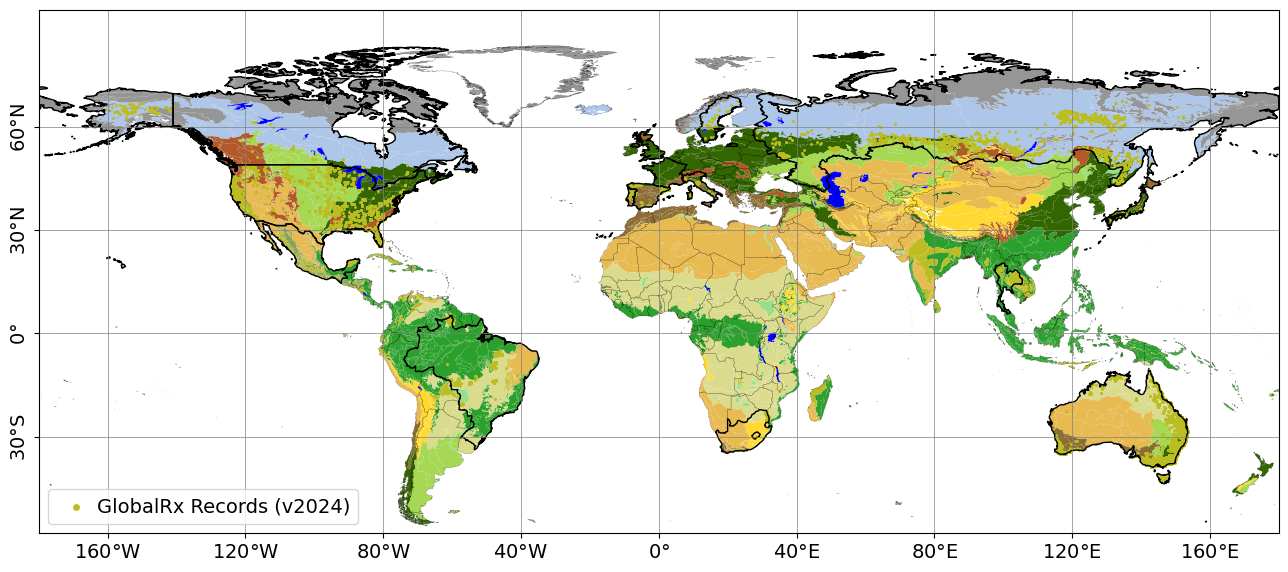

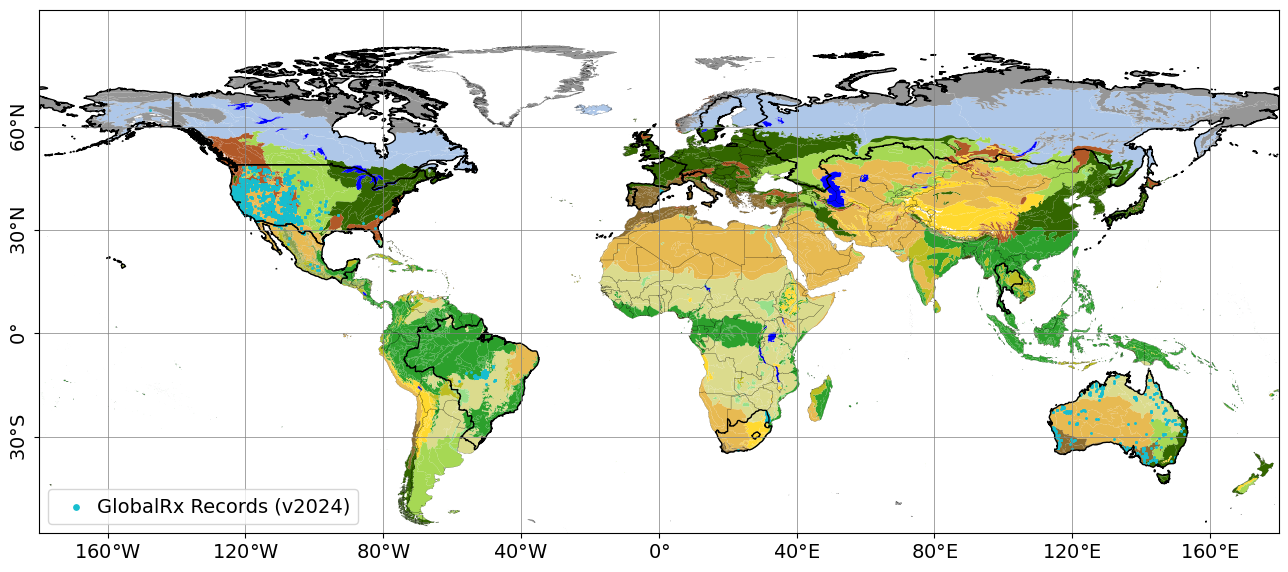

In [30]:
# Set colors for each biome
world_biomes = list(biome_colors.keys())

clusters = np.unique(keep_df['k_cluster'].values)
clust_dict = {i:tab10[i] for i in clusters}
for cluster in clusters:
    fig, ax = plt.subplots(figsize=(16,16))
    
    ax.set_xticks([])
    ax.set_yticks([])
    ax.spines[:].set_visible(True)

    xticks = [-160,-120,-80,-40,0,40,80,120,160]
    yticks = [-60,-30,0,30,60]
    ax.get_xaxis().set_ticks(xticks)
    ax.get_yaxis().set_ticks(yticks)
    xticklabels = [str(abs(i))+'$\degree$W' if i<0 else str(abs(i))+'$\degree$E' for i in xticks]
    xticklabels[4] = '0$\degree$'
    yticklabels = [str(abs(i))+'$\degree$S' if i<0 else str(abs(i))+'$\degree$N' for i in yticks]
    yticklabels[2] = '0$\degree$'
    ax.set_xticklabels(xticklabels,fontsize=14)
    ax.set_yticklabels(yticklabels,fontsize=14,rotation=90,rotation_mode='default',va='center')
    ax.grid(color='gray',linewidth=0.5)

    eco_shp = gpd.read_file('official_teow/wwf_terr_ecos.shp').to_crs('EPSG:4326')
    for biome in world_biomes:
        eco_shp.loc[eco_shp['BIOME']==biome_dict[biome],'BIOME'] = biome

    eco_shp.plot(color=eco_shp['BIOME'].map(biome_colors),ax=ax,categories=world_biomes,aspect='equal',edgecolor='None')

    world_shp = gpd.read_file(glob.glob('world_shp/*.shp')[0]).to_crs('EPSG:4326')
    bounds = world_shp['geometry'].bounds
    xlim = [bounds['minx'].min(),bounds['maxx'].max()]
    ylim = [bounds['miny'].min(),bounds['maxy'].max()]
    ax.set_xlim(xlim);
    ax.set_ylim([-58,94]);
    world_shp.plot(ax=ax,facecolor='None',edgecolor='black',aspect='equal',linewidth=0.1)
    
    ax.scatter(keep_df.loc[keep_df['k_cluster']==cluster,'Longitude'],
               keep_df.loc[keep_df['k_cluster']==cluster,'Latitude'],
               color=clust_dict[cluster],marker='.',s=5,cmap='tab10',
               label='GlobalRx Records (v2024)')
    
    leg = ax.legend(loc='lower left',fontsize=14,handletextpad=0.1)
    leg.legendHandles[0]._sizes = [60]
    countries = ['Australia','Brazil','Canada','France','Italy','Japan','Mexico','Portugal','Russian Federation','South Africa','Spain',
             'Sweden','Thailand','United States of America','U.K. of Great Britain and Northern Ireland']
    for country in countries:
        country_shp = world_shp[world_shp['name']==country]
        country_shp.plot(ax=ax,facecolor='None',edgecolor='Black',aspect='equal',linewidth=1)
# plt.savefig('Figures/GlobalRx_countries_biomes.png',bbox_inches='tight',transparent=True)
